<a href="https://colab.research.google.com/github/SoumayaBeliazidBouzaid/Notebooks/blob/main/notebooks/03_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/03_numpy.ipynb)

# Python pour la physique — 3. NumPy : créer et manipuler des données numériques

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !

In [1]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


# L'objet tableau NumPy

In [2]:
# Notre import habituel.
import numpy as np

## Que sont NumPy et les tableaux NumPy ?

**NumPy** fournit :

- un paquet d'extension de Python pour les tableaux multidimensionnels ;
- une implémentation proche du matériel (efficacité) ;
- un paquet conçu pour le calcul scientifique (commodité) ;
- une implémentation du *calcul orienté tableaux*.

In [3]:
import numpy as np

a = np.array([0, 1, 2, 3])
a

array([0, 1, 2, 3])

Par exemple, un tableau peut contenir :

- les valeurs d'une expérience ou d'une simulation à des pas de temps discrets ;
- un signal enregistré par un appareil de mesure, par exemple une onde sonore ;
- les pixels d'une image, en niveaux de gris ou en couleur ;
- des données 3D mesurées à différentes positions X-Y-Z, par exemple une IRM ;
- …

**Pourquoi c'est utile :** un conteneur économe en mémoire, qui fournit des opérations numériques rapides.

In [4]:
L = range(1000)
%timeit [i**2 for i in L]

96.1 µs ± 31.1 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)


In [5]:
a = np.arange(1000)
%timeit a**2

1.5 µs ± 310 ns per loop (mean ± std. dev. of 7 runs, 1000000 loops each)


La version NumPy est typiquement 10 à 100 fois plus rapide (regardez les temps affichés).

### Documentation de référence

**Sur le web** : <https://numpy.org/doc/>

**Aide interactive** : tapez `np.array?` dans une cellule, ou utilisez la commande `help` de Python :

In [6]:
help(np.array)

Help on built-in function array in module numpy:

array(
    object,
    dtype=None,
    *,
    copy=True,
    order='K',
    subok=False,
    ndmin=0,
    ndmax=0,
    like=None
)
    array(object, dtype=None, *, copy=True, order='K', subok=False, ndmin=0,
          ndmax=0, like=None)

    Create an array.

    Parameters
    ----------
    object : array_like
        An array, any object exposing the array interface, an object whose
        ``__array__`` method returns an array, or any (nested) sequence.
        If object is a scalar, a 0-dimensional array containing object is
        returned.
    dtype : data-type, optional
        The desired data-type for the array. If not given, NumPy will try to use
        a default ``dtype`` that can represent the values (by applying promotion
        rules when necessary.)
    copy : bool, optional
        If ``True`` (default), then the array data is copied. If ``None``,
        a copy will only be made if ``__array__`` returns a copy, if 

### Convention d'importation

La convention recommandée pour importer NumPy est :

In [7]:
import numpy as np

## Créer des tableaux

### Construction manuelle

- **1D** :

In [8]:
a = np.array([0, 1, 2, 3])
a

array([0, 1, 2, 3])

In [9]:
a.ndim

1

In [10]:
a.shape

(4,)

In [11]:
len(a)

4

- **2D, 3D, …** :

In [12]:
b = np.array([[0, 1, 2], [3, 4, 5]])    # tableau 2 x 3
b

array([[0, 1, 2],
       [3, 4, 5]])

In [13]:
b.ndim

2

In [14]:
b.shape

(2, 3)

In [15]:
len(b)     # renvoie la taille de la première dimension

2

In [16]:
c = np.array([[[1], [2]], [[3], [4]]])
c

array([[[1],
        [2]],

       [[3],
        [4]]])

In [17]:
c.shape

(2, 2, 1)

> **Exercice**
>
> - Créez un tableau simple à deux dimensions. Refaites d'abord les exemples ci-dessus, puis créez le vôtre : par exemple, les nombres impairs en ordre décroissant sur la première ligne, et les nombres pairs sur la seconde.
> - Utilisez les fonctions `len` et `np.shape` sur ces tableaux. Quel lien y a-t-il entre elles ? Et avec l'attribut `ndim` ?

In [18]:
# Votre code ici
import numpy as np

# Création d'un tableau à 2 dimensions
T = np.array([[1, 2, 3],
              [4, 5, 6]])

print(T)

[[1 2 3]
 [4 5 6]]


In [21]:
T = np.array([[9, 7, 5, 3, 1],
              [2, 4, 6, 8, 10]])

print("Notre tableau :")
print(T)

Notre tableau :
[[ 9  7  5  3  1]
 [ 2  4  6  8 10]]


In [22]:
print("len(T) =", len(T))
print("np.shape(T) =", np.shape(T))
print("T.ndim =", T.ndim)

len(T) = 2
np.shape(T) = (2, 5)
T.ndim = 2


### Fonctions de création de tableaux

En pratique, on saisit rarement les éléments un par un…

**Régulièrement espacés** :

In [19]:
a = np.arange(10) # 0 .. n-1  (!)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [20]:
b = np.arange(1, 9, 2) # début, fin (exclue), pas
b

array([1, 3, 5, 7])

ou **par nombre de points** :

In [23]:
c = np.linspace(0, 1, 6)   # début, fin, nombre de points
c

array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])

In [24]:
d = np.linspace(0, 1, 5, endpoint=False)
d

array([0. , 0.2, 0.4, 0.6, 0.8])

> 💡 **Astuce**
>
> En physique, `np.linspace` est l'outil de base pour créer un **axe de temps** ou d'espace : `t = np.linspace(0, 10, 1001)` donne 1001 instants de 0 à 10 s.


**Tableaux usuels** :

In [25]:
a = np.ones((3, 3))  # rappel : (3, 3) est un tuple
a

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [26]:
b = np.zeros((2, 2))
b

array([[0., 0.],
       [0., 0.]])

In [27]:
c = np.eye(3)
c

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [28]:
d = np.diag(np.array([1, 2, 3, 4]))
d

array([[1, 0, 0, 0],
       [0, 2, 0, 0],
       [0, 0, 3, 0],
       [0, 0, 0, 4]])

- `np.random` : nombres aléatoires (générateur Mersenne Twister) :

In [29]:
rng = np.random.default_rng(27446968)
a = rng.random(4)       # uniforme dans [0, 1]
a

array([0.64613018, 0.48984931, 0.50851229, 0.22563948])

In [30]:
b = rng.standard_normal(4)      # gaussienne
b

array([-0.38250769, -0.61536465,  0.98131732,  0.59353096])

> **Exercices**
>
> - Expérimentez avec `arange`, `linspace`, `ones`, `zeros`, `eye` et `diag`.
> - Créez différents types de tableaux de nombres aléatoires.
> - Essayez de fixer la graine (*seed*) avant de créer un tableau aléatoire.
> - Regardez la fonction `np.empty`. Que fait-elle ? Quand peut-elle être utile ?



> **Exercice**
>
> - Construisez un tableau contenant : 1 2 3 4 5
> - Construisez un tableau contenant : -5, -4, -3, -2, -1
> - Construisez : 2 4 6 8
> - Construisez 15 nombres équidistants dans l'intervalle [0, 10]

In [36]:
a = np.arange(1, 6)
print(a)

[1 2 3 4 5]


In [38]:
a = np.linspace(0, 10, 5)
print(a)

[ 0.   2.5  5.   7.5 10. ]


In [39]:
a = np.ones(5)
print(a)

[1. 1. 1. 1. 1.]


In [40]:
np.zeros(5)

array([0., 0., 0., 0., 0.])

In [41]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [42]:
a = np.diag([1, 2, 3])
print(a)

[[1 0 0]
 [0 2 0]
 [0 0 3]]


In [43]:
np.random.rand(5)

array([0.91075423, 0.15401184, 0.9835596 , 0.63891105, 0.39676202])

In [44]:
np.random.randint(1, 10, size=5)

array([9, 8, 9, 8, 1])

In [45]:
np.random.randn(5)

array([-8.06930119e-01, -8.25784227e-02, -7.30750539e-01, -2.53744522e-04,
       -1.19235225e-01])

In [46]:
np.random.rand(3, 3)

array([[0.03873206, 0.9525656 , 0.37144318],
       [0.47350869, 0.25203364, 0.75816077],
       [0.98473039, 0.67638159, 0.52407241]])

In [47]:
np.random.seed(42)

a = np.random.rand(5)
print(a)

[0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]


In [48]:
a = np.empty(5)
print(a)

[0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]


In [49]:
#Exercice2
a = np.arange(1, 6)
print(a)

[1 2 3 4 5]


In [50]:
b = np.arange(-5, 0)
print(b)

[-5 -4 -3 -2 -1]


In [51]:
c = np.arange(2, 9, 2)
print(c)

[2 4 6 8]


In [52]:
d = np.linspace(0, 10, 15)
print(d)

[ 0.          0.71428571  1.42857143  2.14285714  2.85714286  3.57142857
  4.28571429  5.          5.71428571  6.42857143  7.14285714  7.85714286
  8.57142857  9.28571429 10.        ]


In [ ]:
#@title Solution { display-mode: "form" }
print(np.arange(1, 6))
print(np.arange(-5, 0))
print(np.arange(2, 10, 2))
print(np.linspace(0, 10, 15))

## Types de données de base

Vous avez peut-être remarqué que, parfois, les éléments d'un tableau s'affichent avec un point final (par exemple `2.` au lieu de `2`). Cela vient d'une différence de type de données (*dtype*) :

In [53]:
a = np.array([1, 2, 3])
a.dtype

dtype('int64')

In [54]:
b = np.array([1., 2., 3.])
b.dtype

dtype('float64')

Différents types de données permettent de stocker les données plus compactement en mémoire, mais la plupart du temps on travaille simplement avec des nombres flottants. Notez que, dans l'exemple ci-dessus, NumPy détecte automatiquement le type à partir des données saisies.

Vous pouvez aussi préciser explicitement le type voulu :

In [55]:
c = np.array([1, 2, 3], dtype=float)
c.dtype

dtype('float64')

Le type **par défaut** est le flottant :

In [56]:
a = np.ones((3, 3))
a.dtype

dtype('float64')

Il existe d'autres types :

**Booléens**

In [57]:
e = np.array([True, False, False, True])
e.dtype

dtype('bool')

**Chaînes de caractères**

In [58]:
f = np.array(['Bonjour', 'Hello', 'Hallo'])
f.dtype     # <--- chaînes de 7 lettres au maximum

dtype('<U7')

**Et bien d'autres** : `int32`, `int64`, `uint32`, `uint64`, `complex128`, …

## Visualisation de base

Maintenant que nous avons nos premiers tableaux, visualisons-les. *Matplotlib* est une bibliothèque de tracé 2D. Dans Colab, les graphiques s'affichent directement sous la cellule.

In [59]:
import matplotlib.pyplot as plt  # la façon propre d'importer

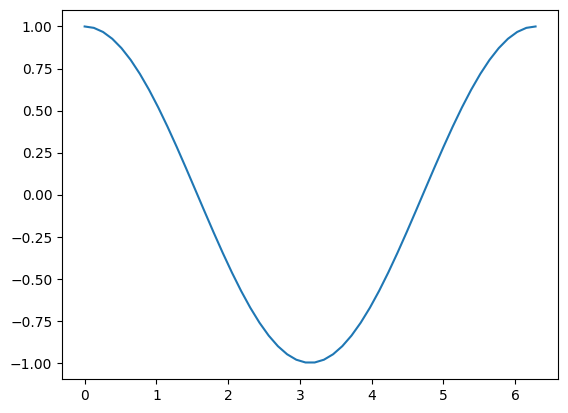

In [60]:
# Données d'exemple
x = np.linspace(0, 2 * np.pi)
y = np.cos(x)

plt.plot(x, y)       # tracé en ligne
plt.show()           # <-- affiche le graphique

- **Tracé 1D** :

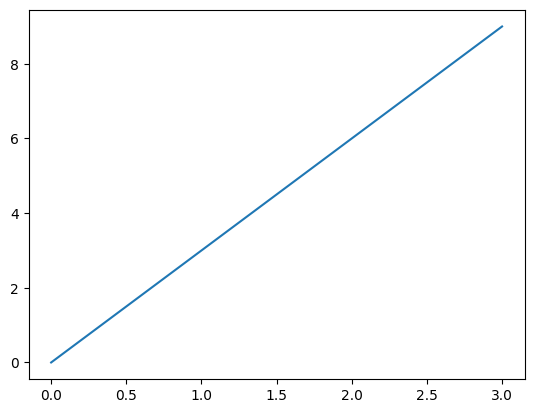

In [61]:
x = np.linspace(0, 3, 20)
y = np.linspace(0, 9, 20)
plt.plot(x, y)       # tracé en ligne
plt.show()

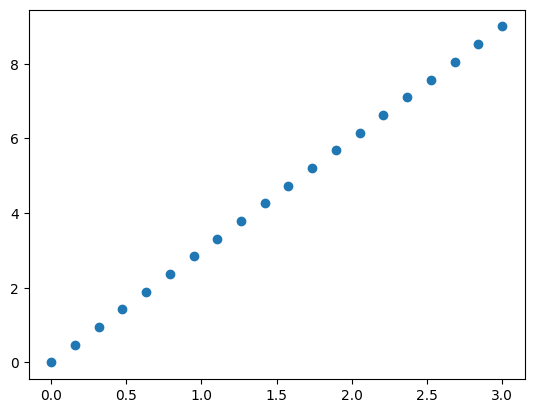

In [62]:
plt.plot(x, y, 'o')  # nuage de points
plt.show()

- **Tableaux 2D** (comme des images) :

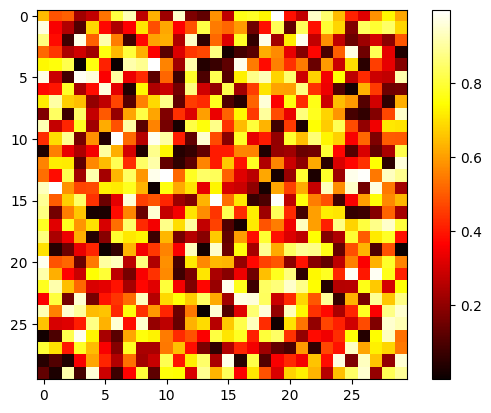

In [63]:
rng = np.random.default_rng(27446968)
image = rng.random((30, 30))
plt.imshow(image, cmap=plt.cm.hot)
plt.colorbar()
plt.show()

Nous détaillerons Matplotlib dans le carnet 4.


> **Exercice**
>
> - Tracez quelques tableaux simples : un cosinus en fonction du temps et une matrice 2D.
> - Essayez la table de couleurs `gray` sur la matrice 2D.

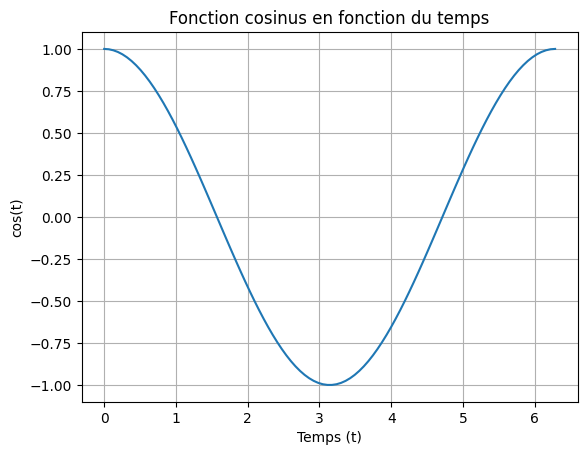

In [64]:
# Votre code ici
import numpy as np
import matplotlib.pyplot as plt

# Création du tableau de temps
t = np.linspace(0, 2*np.pi, 100)

# Calcul du cosinus
y = np.cos(t)

# Tracé du graphique
plt.plot(t, y)

# Ajout des titres et des labels
plt.title("Fonction cosinus en fonction du temps")
plt.xlabel("Temps (t)")
plt.ylabel("cos(t)")

plt.grid()
plt.show()

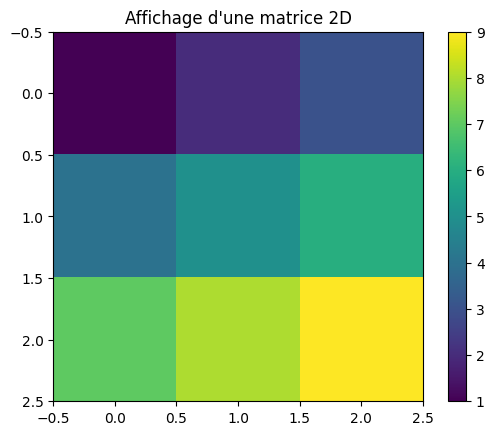

In [65]:
import numpy as np
import matplotlib.pyplot as plt

# Création d'une matrice 2D
matrice = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

# Affichage de la matrice
plt.imshow(matrice)

plt.title("Affichage d'une matrice 2D")
plt.colorbar()
plt.show()

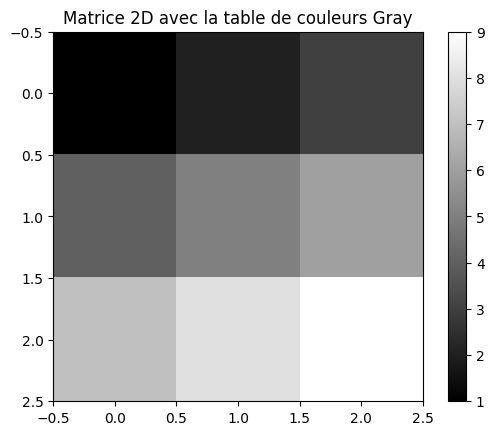

In [66]:
import numpy as np
import matplotlib.pyplot as plt

matrice = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

plt.imshow(matrice, cmap='gray')

plt.title("Matrice 2D avec la table de couleurs Gray")
plt.colorbar()
plt.show()

## Indexation et découpage

On accède aux éléments d'un tableau, et on les modifie, comme pour les autres séquences Python (par exemple les listes) :

In [67]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [68]:
a[0], a[2], a[-1]

(np.int64(0), np.int64(2), np.int64(9))

> ⚠️ **Attention**
>
> Les indices commencent à 0, comme pour les autres séquences Python (et le C/C++). En Fortran ou Matlab, ils commencent à 1.


L'idiome Python habituel pour inverser une séquence fonctionne :

In [69]:
a[::-1]

array([9, 8, 7, 6, 5, 4, 3, 2, 1, 0])

Pour les tableaux multidimensionnels, les indices sont des tuples d'entiers :

In [70]:
a = np.diag(np.arange(3))
a

array([[0, 0, 0],
       [0, 1, 0],
       [0, 0, 2]])

In [71]:
a[1, 1]

np.int64(1)

In [72]:
a[2, 1] = 10 # troisième ligne, deuxième colonne
a

array([[ 0,  0,  0],
       [ 0,  1,  0],
       [ 0, 10,  2]])

In [73]:
a[1]

array([0, 1, 0])

> 📝 **Note**
>
> - En 2D, la première dimension correspond aux **lignes**, la seconde aux **colonnes**.
> - Pour un tableau multidimensionnel `a`, `a[0]` signifie : tous les éléments des dimensions non précisées.


**Découpage** (*slicing*) : les tableaux, comme les autres séquences Python, peuvent être découpés :

In [74]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [75]:
a[2:9:3] # [début:fin:pas]

array([2, 5, 8])

Notez que le dernier indice n'est pas inclus !

In [76]:
a[:4]

array([0, 1, 2, 3])

Les trois composantes ne sont pas toutes obligatoires : par défaut, `début` vaut 0, `fin` est le dernier élément et `pas` vaut 1 :

In [77]:
a[1:3]

array([1, 2])

In [78]:
a[::2]

array([0, 2, 4, 6, 8])

In [79]:
a[3:]

array([3, 4, 5, 6, 7, 8, 9])

Un petit résumé illustré de l'indexation et du découpage NumPy :

![Indexation NumPy](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/pyximages/numpy_indexing.png)

On peut aussi combiner affectation et découpage :

In [80]:
a = np.arange(10)
a[5:] = 10
a

array([ 0,  1,  2,  3,  4, 10, 10, 10, 10, 10])

In [81]:
b = np.arange(5)
a[5:] = b[::-1]
a

array([0, 1, 2, 3, 4, 4, 3, 2, 1, 0])

> **Exercice**
>
> - Essayez les différentes variantes de découpage avec `début`, `fin` et `pas` : à partir d'un `linspace`, obtenez les nombres impairs en ordre décroissant et les nombres pairs en ordre croissant.
> - Reproduisez les découpages du schéma ci-dessus. Vous pouvez créer le tableau avec l'expression :
>
> ```python
> np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]
> ```

In [82]:
# Votre code ici
import numpy as np

tab = np.linspace(1, 20, 20)

print(tab)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20.]


In [83]:
impairs = tab[18::-2]

print(impairs)

[19. 17. 15. 13. 11.  9.  7.  5.  3.  1.]


In [84]:
pairs = tab[1::2]

print(pairs)

[ 2.  4.  6.  8. 10. 12. 14. 16. 18. 20.]


In [85]:
tab = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]

print(tab)

[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]


In [86]:
print(tab[0, :])

[0 1 2 3 4 5]


In [87]:
print(tab[:, 0])

[ 0 10 20 30 40 50]


In [88]:
print(tab[:3, :])

[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]]


In [89]:
print(tab[:, :3])

[[ 0  1  2]
 [10 11 12]
 [20 21 22]
 [30 31 32]
 [40 41 42]
 [50 51 52]]


In [90]:
print(tab[::2, :])

[[ 0  1  2  3  4  5]
 [20 21 22 23 24 25]
 [40 41 42 43 44 45]]


In [91]:
print(tab[:, ::2])

[[ 0  2  4]
 [10 12 14]
 [20 22 24]
 [30 32 34]
 [40 42 44]
 [50 52 54]]


In [92]:
print(tab[::-1, :])

[[50 51 52 53 54 55]
 [40 41 42 43 44 45]
 [30 31 32 33 34 35]
 [20 21 22 23 24 25]
 [10 11 12 13 14 15]
 [ 0  1  2  3  4  5]]


In [93]:
print(tab[:, ::-1])

[[ 5  4  3  2  1  0]
 [15 14 13 12 11 10]
 [25 24 23 22 21 20]
 [35 34 33 32 31 30]
 [45 44 43 42 41 40]
 [55 54 53 52 51 50]]


> **Exercice : création de tableaux**
>
>
> Créez les tableaux suivants (avec les bons types de données) :
>
> ```python
> [[1, 1, 1, 1],
>  [1, 1, 1, 1],
>  [1, 1, 1, 2],
>  [1, 6, 1, 1]]
>
> [[0., 0., 0., 0., 0.],
>  [2., 0., 0., 0., 0.],
>  [0., 3., 0., 0., 0.],
>  [0., 0., 4., 0., 0.],
>  [0., 0., 0., 5., 0.],
>  [0., 0., 0., 0., 6.]]
> ```
>
> *Objectif* : 3 instructions pour chacun.
>
> *Indice* : on accède aux éléments individuels comme dans une liste, par exemple `a[1]` ou `a[1, 2]`. Examinez aussi la docstring de `diag`.

In [94]:
import numpy as np

a = np.ones((4, 4), dtype=int)
a[2, 3] = 2
a[3, 1] = 6

print(a)

[[1 1 1 1]
 [1 1 1 1]
 [1 1 1 2]
 [1 6 1 1]]


In [95]:
b = np.diag([2., 3., 4., 5., 6.], k=-1)
b = np.pad(b, ((0, 0), (0, 1)))
print(b)

[[0. 0. 0. 0. 0. 0. 0.]
 [2. 0. 0. 0. 0. 0. 0.]
 [0. 3. 0. 0. 0. 0. 0.]
 [0. 0. 4. 0. 0. 0. 0.]
 [0. 0. 0. 5. 0. 0. 0.]
 [0. 0. 0. 0. 6. 0. 0.]]


In [96]:
np.diag([1, 2, 3])

array([[1, 0, 0],
       [0, 2, 0],
       [0, 0, 3]])

In [97]:
#@title Solution { display-mode: "form" }
a = np.ones((4, 4), dtype=int)
a[3, 1] = 6
a[2, 3] = 2
print(a)

b = np.zeros((6, 5))
b[1:] = np.diag(np.arange(2, 7))
print(b)

[[1 1 1 1]
 [1 1 1 1]
 [1 1 1 2]
 [1 6 1 1]]
[[0. 0. 0. 0. 0.]
 [2. 0. 0. 0. 0.]
 [0. 3. 0. 0. 0.]
 [0. 0. 4. 0. 0.]
 [0. 0. 0. 5. 0.]
 [0. 0. 0. 0. 6.]]


> **Exercice : le pavage (*tiling*)**
>
>
> Parcourez la documentation de `np.tile` et utilisez cette fonction pour construire le tableau :
>
> ```python
> [[4, 3, 4, 3, 4, 3],
>  [2, 1, 2, 1, 2, 1],
>  [4, 3, 4, 3, 4, 3],
>  [2, 1, 2, 1, 2, 1]]
> ```

In [98]:
# Votre code ici
import numpy as np

a = np.array([[4, 3],
              [2, 1]])

b = np.tile(a, (2, 3))

print(b)

[[4 3 4 3 4 3]
 [2 1 2 1 2 1]
 [4 3 4 3 4 3]
 [2 1 2 1 2 1]]


In [99]:
#@title Solution { display-mode: "form" }
bloc = np.array([[4, 3], [2, 1]])
a = np.tile(bloc, (2, 3))
a

array([[4, 3, 4, 3, 4, 3],
       [2, 1, 2, 1, 2, 1],
       [4, 3, 4, 3, 4, 3],
       [2, 1, 2, 1, 2, 1]])

## Copies et vues

Une opération de découpage crée une **vue** du tableau d'origine, c'est-à-dire simplement une autre façon d'accéder aux données. Le tableau d'origine n'est donc pas copié en mémoire. On peut utiliser `np.may_share_memory()` pour vérifier si deux tableaux partagent le même bloc mémoire (attention : cette fonction utilise des heuristiques et peut donner des faux positifs).

**Quand on modifie la vue, le tableau d'origine est modifié aussi** :

In [100]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [101]:
b = a[::2]
b

array([0, 2, 4, 6, 8])

In [102]:
np.may_share_memory(a, b)

True

In [103]:
b[0] = 12
b

array([12,  2,  4,  6,  8])

In [104]:
a   # (!)

array([12,  1,  2,  3,  4,  5,  6,  7,  8,  9])

In [105]:
a = np.arange(10)
c = a[::2].copy()  # on force une copie
c[0] = 12
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [106]:
np.may_share_memory(a, c)

False

Ce comportement peut surprendre au début… mais il permet d'économiser à la fois de la mémoire et du temps.

### Exemple détaillé : le crible d'Ératosthène

Calculons les nombres premiers entre 0 et 99 avec un crible.

D'abord, construisons un tableau booléen `est_premier` de forme (100,), rempli de `True` :

In [107]:
est_premier = np.ones((100,), dtype=bool)

Ensuite, barrons 0 et 1, qui ne sont pas premiers :

In [108]:
est_premier[:2] = 0

Pour chaque entier `j` à partir de 2, barrons ses multiples supérieurs :

In [109]:
N_max = int(np.sqrt(len(est_premier) - 1))
for j in range(2, N_max + 1):
    est_premier[2*j::j] = False

Parcourez `help(np.nonzero)` et affichez les nombres premiers.

In [110]:
# Votre code ici
premiers = []

for n in a:
    if n > 1 and all(n % i != 0 for i in range(2, int(np.sqrt(n)) + 1)):
        premiers.append(n)

print(premiers)

indices = np.nonzero(np.isin(a, premiers))

print(indices)
print(a[indices])

[np.int64(2), np.int64(3), np.int64(5), np.int64(7)]
(array([2, 3, 5, 7]),)
[2 3 5 7]


In [111]:
#@title Solution { display-mode: "form" }
np.nonzero(est_premier)[0]

array([ 2,  3,  5,  7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59,
       61, 67, 71, 73, 79, 83, 89, 97])

## Indexation avancée (*fancy indexing*)

Les tableaux NumPy peuvent être indexés avec des découpages, mais aussi avec des tableaux de booléens ou d'entiers (**masques**). Cette méthode s'appelle *fancy indexing*. Elle crée des **copies, pas des vues**.

### Avec des masques booléens

In [112]:
rng = np.random.default_rng(27446968)
a = rng.integers(0, 21, 15)
a

array([ 3, 13, 12, 10, 10, 10, 18,  4,  8,  5,  6, 11, 12, 17,  3])

In [113]:
(a % 3 == 0)

array([ True, False,  True, False, False, False,  True, False, False,
       False,  True, False,  True, False,  True])

In [114]:
masque = (a % 3 == 0)
extrait_de_a = a[masque] # ou bien a[a%3==0]
extrait_de_a             # extrait un sous-tableau avec le masque

array([ 3, 12, 18,  6, 12,  3])

L'indexation par masque est très utile pour affecter une nouvelle valeur à un sous-tableau :

In [115]:
a[a % 3 == 0] = -1
a

array([-1, 13, -1, 10, 10, 10, -1,  4,  8,  5, -1, 11, -1, 17, -1])

En physique, c'est idéal pour **filtrer des mesures** : par exemple, ne garder que les valeurs physiquement acceptables.

In [116]:
mesures = np.array([2.1, 2.3, -999.0, 2.2, 2.4, -999.0, 2.0])   # -999 : mesure invalide
valides = mesures[mesures > 0]
valides, valides.mean()

(array([2.1, 2.3, 2.2, 2.4, 2. ]), np.float64(2.2))

### Avec un tableau d'entiers

In [117]:
a = np.arange(0, 100, 10)
a

array([ 0, 10, 20, 30, 40, 50, 60, 70, 80, 90])

L'indexation peut se faire avec un tableau d'entiers, où le même indice peut être répété plusieurs fois :

In [118]:
a[[2, 3, 2, 4, 2]]  # note : [2, 3, 2, 4, 2] est une liste Python

array([20, 30, 20, 40, 20])

On peut affecter de nouvelles valeurs avec ce type d'indexation :

In [119]:
a[[9, 7]] = -100
a

array([   0,   10,   20,   30,   40,   50,   60, -100,   80, -100])

**Astuce** : quand un nouveau tableau est créé par indexation avec un tableau d'entiers, il a la même forme que le tableau d'indices :

In [121]:
a = np.arange(10)
idx = np.array([[3, 4], [9, 7]])
idx.shape

(2, 2)

In [ ]:
a[idx]

L'image ci-dessous illustre diverses applications du *fancy indexing* :

![Fancy indexing NumPy](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/pyximages/numpy_fancy_indexing.png)


> **Exercice**
>
> - Reproduisez à nouveau l'indexation avancée du schéma ci-dessus.
> - Utilisez l'indexation avancée à gauche et la création de tableau à droite pour affecter des valeurs, par exemple en mettant à zéro certaines parties du tableau du schéma.

In [129]:
# Votre code ici
import numpy as np

# 1. Création du tableau 2D
a = np.arange(6) + np.arange(0, 51, 10)[:, np.newaxis]

print("Tableau initial :")
print(a)

# 2. Indexation avancée : sélectionner plusieurs éléments
print("\nSélection de plusieurs éléments :")
print(a[[0, 1, 2], [1, 2, 3]])

# 3. Mettre certains éléments à zéro
a[[0, 1, 2], [1, 2, 3]] = 0

print("\nAprès modification de certains éléments :")
print(a)

# 4. Mettre plusieurs lignes à zéro avec un tableau de zéros
a[[0, 2], :] = np.zeros((2, 6))

print("\nAprès mise à zéro des lignes 0 et 2 :")
print(a)

# 5. Affecter des valeurs à plusieurs éléments
a[[0, 1, 2], [0, 1, 2]] = [100, 200, 300]

print("\nAprès affectation de nouvelles valeurs :")
print(a)

Tableau initial :
[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]

Sélection de plusieurs éléments :
[ 1 12 23]

Après modification de certains éléments :
[[ 0  0  2  3  4  5]
 [10 11  0 13 14 15]
 [20 21 22  0 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]

Après mise à zéro des lignes 0 et 2 :
[[ 0  0  0  0  0  0]
 [10 11  0 13 14 15]
 [ 0  0  0  0  0  0]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]

Après affectation de nouvelles valeurs :
[[100   0   0   0   0   0]
 [ 10 200   0  13  14  15]
 [  0   0 300   0   0   0]
 [ 30  31  32  33  34  35]
 [ 40  41  42  43  44  45]
 [ 50  51  52  53  54  55]]


# Opérations numériques sur les tableaux

## Opérations élément par élément

### Opérations de base

Avec des scalaires :

In [122]:
a = np.array([1, 2, 3, 4])
a + 1

array([2, 3, 4, 5])

In [123]:
2 ** a

array([ 2,  4,  8, 16])

Toute l'arithmétique opère élément par élément :

In [124]:
b = np.ones(4) + 1
a - b

array([-1.,  0.,  1.,  2.])

In [125]:
a * b

array([2., 4., 6., 8.])

In [126]:
j = np.arange(5)
2**(j + 1) - j

array([ 2,  3,  6, 13, 28])

Ces opérations sont bien sûr beaucoup plus rapides qu'en Python pur :

In [127]:
a = np.arange(10000)
%timeit a + 1

4.21 µs ± 126 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)


In [128]:
l = range(10000)
%timeit [i+1 for i in l]

819 µs ± 244 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


> ⚠️ **Attention**
>
> **La multiplication de tableaux n'est pas la multiplication matricielle.**

In [130]:
c = np.ones((3, 3))
c * c                   # PAS une multiplication matricielle !

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

**Multiplication matricielle :**

In [131]:
c @ c

array([[3., 3., 3.],
       [3., 3., 3.],
       [3., 3., 3.]])

> **Exercice**
>
> - Essayez des opérations arithmétiques simples, élément par élément : ajoutez les éléments pairs aux éléments impairs.
> - Comparez leur durée avec leurs équivalents en Python pur, avec `%timeit`.
> - Générez :
>   - `[2**0, 2**1, 2**2, 2**3, 2**4]`
>   - `a_j = 2^(3*j) - j`

In [132]:
# Votre code ici
import numpy as np

# 1. Créer un tableau de nombres
a = np.arange(1, 11)

# Séparer les nombres pairs et impairs
pairs = a[a % 2 == 0]
impairs = a[a % 2 != 0]

# Addition élément par élément
resultat = pairs + impairs

print("Nombres pairs :", pairs)
print("Nombres impairs :", impairs)
print("Addition pairs + impairs :", resultat)


# 2. Comparer les performances avec %timeit

# Avec NumPy
print("\nTemps d'exécution avec NumPy :")
%timeit pairs + impairs

# Avec Python pur
pairs_list = pairs.tolist()
impairs_list = impairs.tolist()

print("\nTemps d'exécution avec Python pur :")
%timeit [x + y for x, y in zip(pairs_list, impairs_list)]


# 3. Générer les puissances de 2
puissances = 2 ** np.arange(5)

print("\nPuissances de 2 :")
print(puissances)


# 4. Générer a_j = 2^(3*j) - j
j = np.arange(5)
a_j = 2 ** (3 * j) - j

print("\nValeurs de a_j :")
print(a_j)

Nombres pairs : [ 2  4  6  8 10]
Nombres impairs : [1 3 5 7 9]
Addition pairs + impairs : [ 3  7 11 15 19]

Temps d'exécution avec NumPy :
852 ns ± 290 ns per loop (mean ± std. dev. of 7 runs, 1000000 loops each)

Temps d'exécution avec Python pur :
533 ns ± 7.35 ns per loop (mean ± std. dev. of 7 runs, 1000000 loops each)

Puissances de 2 :
[ 1  2  4  8 16]

Valeurs de a_j :
[   1    7   62  509 4092]


### Autres opérations

#### Comparaisons

In [133]:
a = np.array([1, 2, 3, 4])
b = np.array([4, 2, 2, 4])
a == b

array([False,  True, False,  True])

In [134]:
a > b

array([False, False,  True, False])

Comparaisons de tableaux entiers :

In [135]:
a = np.array([1, 2, 3, 4])
b = np.array([4, 2, 2, 4])
c = np.array([1, 2, 3, 4])
np.array_equal(a, b)

False

In [136]:
np.array_equal(a, c)

True

#### Opérations logiques

In [137]:
a = np.array([1, 1, 0, 0], dtype=bool)
b = np.array([1, 0, 1, 0], dtype=bool)
np.logical_or(a, b)

array([ True,  True,  True, False])

In [138]:
np.logical_and(a, b)

array([ True, False, False, False])

#### Fonctions transcendantes

In [139]:
a = np.arange(5)
np.sin(a)

array([ 0.        ,  0.84147098,  0.90929743,  0.14112001, -0.7568025 ])

In [140]:
np.exp(a)

array([ 1.        ,  2.71828183,  7.3890561 , 20.08553692, 54.59815003])

In [141]:
np.log(np.exp(a))

array([0., 1., 2., 3., 4.])

#### Formes incompatibles

In [142]:
# Erreur volontaire : les formes sont incompatibles
a = np.arange(4)
a + np.array([1, 2])

ValueError: operands could not be broadcast together with shapes (4,) (2,) 

*Et le broadcasting ?* Nous y reviendrons plus loin.

#### Transposition

In [143]:
a = np.triu(np.ones((3, 3)), 1)   # voir help(np.triu)
a

array([[0., 1., 1.],
       [0., 0., 1.],
       [0., 0., 0.]])

In [144]:
a.T

array([[0., 0., 0.],
       [1., 0., 0.],
       [1., 1., 0.]])

Rappelez-vous : **la transposée est une vue** du tableau d'origine :

In [145]:
a = np.arange(9).reshape(3, 3)
a.T[0, 2] = 999
a.T

array([[  0,   3, 999],
       [  1,   4,   7],
       [  2,   5,   8]])

In [146]:
a

array([[  0,   1,   2],
       [  3,   4,   5],
       [999,   7,   8]])

#### Algèbre linéaire

Le sous-module `numpy.linalg` implémente l'algèbre linéaire de base, comme la résolution de systèmes linéaires ou la décomposition en valeurs singulières. Son efficacité n'est toutefois pas garantie ; nous recommandons plutôt `scipy.linalg` (voir carnet 5).


> **Exercice**
>
> - Regardez l'aide de `np.allclose`. Quand peut-elle être utile ?
> - Regardez l'aide de `np.triu` et `np.tril`.

In [147]:
import numpy as np

# 1. Utilisation de np.allclose()
a = np.array([1.0, 2.0, 3.0])
b = np.array([1.0, 2.0000001, 3.0])

print("Les deux tableaux sont-ils proches ?")
print(np.allclose(a, b))

# Comparaison avec des valeurs différentes
c = np.array([1.0, 5.0, 3.0])
print("Comparaison avec un tableau différent :")
print(np.allclose(a, c))


# 2. Utilisation de np.triu()
matrice = np.arange(1, 17).reshape(4, 4)

print("\nMatrice initiale :")
print(matrice)

print("\nMatrice triangulaire supérieure :")
print(np.triu(matrice))


# 3. Utilisation de np.tril()
print("\nMatrice triangulaire inférieure :")
print(np.tril(matrice))

Les deux tableaux sont-ils proches ?
True
Comparaison avec un tableau différent :
False

Matrice initiale :
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]

Matrice triangulaire supérieure :
[[ 1  2  3  4]
 [ 0  6  7  8]
 [ 0  0 11 12]
 [ 0  0  0 16]]

Matrice triangulaire inférieure :
[[ 1  0  0  0]
 [ 5  6  0  0]
 [ 9 10 11  0]
 [13 14 15 16]]


## Réductions de base

### Calculer des sommes

In [148]:
x = np.array([1, 2, 3, 4])
np.sum(x)

np.int64(10)

In [149]:
x.sum()

np.int64(10)

![Réductions](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/intro/numpy/images/reductions.png)

Somme par lignes et par colonnes :

In [150]:
x = np.array([[1, 1], [2, 2]])
x

array([[1, 1],
       [2, 2]])

In [151]:
x.sum(axis=0)   # colonnes (première dimension)

array([3, 3])

In [152]:
x[:, 0].sum(), x[:, 1].sum()

(np.int64(3), np.int64(3))

In [153]:
x.sum(axis=1)   # lignes (seconde dimension)

array([2, 4])

In [154]:
x[0, :].sum(), x[1, :].sum()

(np.int64(2), np.int64(4))

Même principe en dimensions supérieures :

In [155]:
rng = np.random.default_rng(27446968)
x = rng.random((2, 2, 2))
x.sum(axis=2)[0, 1]

np.float64(0.7341517644004746)

In [156]:
x[0, 1, :].sum()

np.float64(0.7341517644004746)

### Autres réductions

Elles fonctionnent de la même façon (et acceptent `axis=`).

#### Extrema

In [157]:
x = np.array([1, 3, 2])
x.min()

np.int64(1)

In [158]:
x.max()

np.int64(3)

In [159]:
x.argmin()  # indice du minimum

np.int64(0)

In [160]:
x.argmax()  # indice du maximum

np.int64(1)

#### Opérations logiques

In [161]:
np.all([True, True, False])

np.False_

In [162]:
np.any([True, True, False])

np.True_

Cela peut servir à comparer des tableaux :

In [163]:
a = np.zeros((100, 100))
np.any(a != 0)

np.False_

In [164]:
np.all(a == a)

np.True_

In [166]:
a = np.array([1, 2, 3, 2])
b = np.array([2, 2, 3, 2])
c = np.array([6, 4, 4, 5])
((a <= b) & (b <= c)).all()

np.True_

**Statistiques :**

In [167]:
x = np.array([1, 2, 3, 1])
y = np.array([[1, 2, 3], [5, 6, 1]])
x.mean()

np.float64(1.75)

In [168]:
np.median(x)

np.float64(1.5)

In [169]:
np.median(y, axis=-1) # dernier axe

array([2., 5.])

In [170]:
x.std()          # écart-type de la population entière

np.float64(0.82915619758885)

… et bien d'autres (le mieux est de les apprendre au fur et à mesure).


> **Exercice**
>
> Puisqu'il existe `sum`, quelle autre fonction vous attendez-vous à trouver ? Quelle est la différence entre `sum` et `cumsum` ?

In [171]:
import numpy as np

# Création d'un tableau
a = np.array([1, 2, 3, 4, 5])

# 1. Somme totale
print("Somme avec sum :", np.sum(a))

# 2. Somme cumulative
print("Somme cumulative avec cumsum :", np.cumsum(a))

# 3. Comparaison avec Python pur
print("Somme Python :", sum(a))

# 4. Somme cumulative avec Python pur
cumul = []
total = 0

for x in a:
    total += x
    cumul.append(total)

print("Cumul Python :", cumul)

Somme avec sum : 15
Somme cumulative avec cumsum : [ 1  3  6 10 15]
Somme Python : 15
Cumul Python : [np.int64(1), np.int64(3), np.int64(6), np.int64(10), np.int64(15)]


### Exemple détaillé : la diffusion par marche aléatoire

Considérons une marche aléatoire 1D simple : à chaque pas de temps, le marcheur saute à droite ou à gauche avec une probabilité égale.

Nous cherchons la distance typique à l'origine d'un marcheur après `t` sauts à gauche ou à droite. Nous allons simuler de nombreux « marcheurs » pour trouver cette loi, avec les astuces du calcul sur tableaux : nous créons un tableau 2D avec les « histoires » (chaque marcheur a la sienne) dans une direction, et le temps dans l'autre :

![Schéma de la marche aléatoire](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/intro/numpy/random_walk_schema.png)

In [173]:
n_histoires = 1000 # nombre de marcheurs
t_max = 200        # durée pendant laquelle on suit le marcheur

On tire au hasard tous les pas, 1 ou -1 :

In [174]:
t = np.arange(t_max)
rng = np.random.default_rng()
pas = 2 * rng.integers(0, 1 + 1, (n_histoires, t_max)) - 1 # +1 car la borne haute est exclue
np.unique(pas) # Vérification : tous les pas valent 1 ou -1

array([-1,  1])

On construit les marches en sommant les pas le long du temps :

In [175]:
positions = np.cumsum(pas, axis=1) # axis = 1 : dimension du temps
dist_carree = positions**2

On fait la moyenne sur l'axe des histoires :

In [176]:
dist_carree_moy = np.mean(dist_carree, axis=0)

Traçons les résultats :

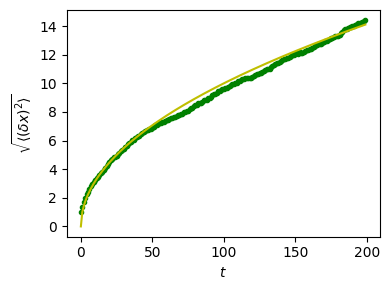

In [177]:
plt.figure(figsize=(4, 3))
plt.plot(t, np.sqrt(dist_carree_moy), 'g.', t, np.sqrt(t), 'y-')
plt.xlabel(r"$t$")
plt.ylabel(r"$\sqrt{\langle (\delta x)^2 \rangle}$")
plt.tight_layout() # laisse assez de place pour les légendes
plt.show()

Nous retrouvons un résultat bien connu en physique : la distance quadratique moyenne (RMS) croît comme la **racine carrée du temps**.

## Récapitulatif intermédiaire

| Type d'opération | Fonctions NumPy              |
| ---------------- | ---------------------------- |
| arithmétique     | `sum`, `prod`, `mean`, `std` |
| extrema          | `min`, `max`                 |
| logique          | `all`, `any`                 |

Rappelez-vous aussi l'argument `axis` pour choisir la dimension sur laquelle appliquer l'opération :

In [178]:
arr = np.array([[99, 12], [11, 2]])
arr

array([[99, 12],
       [11,  2]])

In [179]:
# Sans axis=, l'opération s'applique à tout le tableau (aplati, 1D).
np.min(arr)

np.int64(2)

In [180]:
# Opération le long du premier axe (lignes).
np.min(arr, axis=0)

array([11,  2])

In [181]:
# Opération le long du second axe (colonnes).
np.min(arr, axis=1)

array([12,  2])

> **Exercice : lire des données d'un fichier**
>
>
> NumPy lit et écrit facilement des fichiers texte avec `np.savetxt` et `np.loadtxt`. Créons d'abord un petit fichier de mesures :
>

In [182]:
rng = np.random.default_rng(0)
mesures = rng.normal(loc=5.0, scale=0.3, size=(5, 4))
np.savetxt('un_tableau.txt', mesures)

Rechargeons-le :

In [183]:
un_tableau = np.loadtxt('un_tableau.txt')
un_tableau

array([[5.03771907, 4.96036854, 5.1921268 , 5.03147004],
       [4.83929919, 5.10847852, 5.39120001, 5.28412429],
       [4.78887943, 4.62037356, 4.81301766, 5.01239779],
       [4.30249077, 4.9343625 , 4.62622672, 4.78031979],
       [4.83672231, 4.90510995, 5.12348916, 5.31275401]])

1. Vérifiez si tous les éléments de `un_tableau` sont égaux à 1.
2. Vérifiez si au moins un élément est égal à 1.
3. Calculez la moyenne et l'écart-type.
4. Défi : écrivez une fonction `mon_std` qui calcule l'écart-type des éléments du tableau, en n'utilisant de NumPy que `np.sum`. Vérifiez que votre fonction donne une valeur proche de `np.std` (utilisez `np.allclose`).

In [184]:
# Votre code ici

import numpy as np

# 1. Créer et lire le fichier
rng = np.random.default_rng(0)
mesures = rng.normal(loc=5.0, scale=0.3, size=(5, 4))
np.savetxt('un_tableau.txt', mesures)

un_tableau = np.loadtxt('un_tableau.txt')
print("Tableau chargé :")
print(un_tableau)

# 1. Vérifier si tous les éléments sont égaux à 1
print("\n1. Tous les éléments sont égaux à 1 :", np.all(un_tableau == 1))

# 2. Vérifier si au moins un élément est égal à 1
print("2. Au moins un élément est égal à 1 :", np.any(un_tableau == 1))

# 3. Calculer la moyenne et l'écart-type
moyenne = np.mean(un_tableau)
ecart_type = np.std(un_tableau)

print("\n3. Moyenne :", moyenne)
print("   Écart-type :", ecart_type)

# 4. Fonction qui calcule l'écart-type en utilisant uniquement np.sum
def mon_std(tab):
    moyenne = np.sum(tab) / tab.size
    variance = np.sum((tab - moyenne) ** 2) / tab.size
    return np.sqrt(variance)

resultat = mon_std(un_tableau)

print("\n4. Écart-type calculé avec mon_std :", resultat)
print("   Écart-type avec np.std :", np.std(un_tableau))
print("   Les résultats sont proches :", np.allclose(resultat, np.std(un_tableau)))


Tableau chargé :
[[5.03771907 4.96036854 5.1921268  5.03147004]
 [4.83929919 5.10847852 5.39120001 5.28412429]
 [4.78887943 4.62037356 4.81301766 5.01239779]
 [4.30249077 4.9343625  4.62622672 4.78031979]
 [4.83672231 4.90510995 5.12348916 5.31275401]]

1. Tous les éléments sont égaux à 1 : False
2. Au moins un élément est égal à 1 : False

3. Moyenne : 4.9450465047713825
   Écart-type : 0.25526270692928

4. Écart-type calculé avec mon_std : 0.25526270692928
   Écart-type avec np.std : 0.25526270692928
   Les résultats sont proches : True


In [185]:
#@title Solution { display-mode: "form" }
# 1. Tous les éléments sont-ils égaux à 1 ?
print(np.all(un_tableau == 1))

# 2. Au moins un élément est-il égal à 1 ?
print(np.any(un_tableau == 1))

# 3. Moyenne et écart-type.
print('Moyenne', np.mean(un_tableau))
print('Écart-type', np.std(un_tableau))

# 4. Défi
def mon_std(a):
    n = a.size
    m = np.sum(a) / n
    return np.sqrt(np.sum((a - m) ** 2) / n)

assert np.allclose(mon_std(un_tableau), np.std(un_tableau))
assert np.allclose(mon_std(un_tableau.ravel()), np.std(un_tableau))
print("Vérifications réussies")

False
False
Moyenne 4.9450465047713825
Écart-type 0.25526270692928
Vérifications réussies


> 💡 **Astuce**
>
> **Avec Google Drive** : pour charger un fichier de données placé dans votre Drive, montez-le avec `from google.colab import drive; drive.mount('/content/drive')`, puis lisez-le avec par exemple `np.loadtxt('/content/drive/MyDrive/mes_donnees/mesures.txt')`.

## Broadcasting (diffusion)

- Les opérations de base sur les tableaux `numpy` (addition, etc.) se font élément par élément.
- Cela fonctionne sur des tableaux de même taille.
- **Néanmoins**, il est aussi possible d'opérer sur des tableaux de tailles différentes si *NumPy* peut les transformer pour qu'ils aient tous la même taille : cette conversion s'appelle le **broadcasting**.

L'image ci-dessous donne un exemple de broadcasting :

![Broadcasting](https://raw.githubusercontent.com/scipy-lectures/scipy-lecture-notes/master/intro/numpy/images/numpy_broadcasting.png)

Vérifions :

In [186]:
a = np.tile(np.arange(0, 40, 10), (3, 1)).T
a

array([[ 0,  0,  0],
       [10, 10, 10],
       [20, 20, 20],
       [30, 30, 30]])

In [187]:
b = np.array([0, 1, 2])
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

Nous avons déjà utilisé le broadcasting sans le savoir !

In [188]:
a = np.ones((4, 5))
a[0] = 2  # on affecte un tableau de dimension 0 à un tableau de dimension 1
a

array([[2., 2., 2., 2., 2.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])

Une astuce utile :

In [189]:
a = np.arange(0, 40, 10)
a.shape

(4,)

In [190]:
a = a[:, np.newaxis]  # ajoute un nouvel axe -> tableau 2D
a.shape

(4, 1)

In [191]:
a

array([[ 0],
       [10],
       [20],
       [30]])

In [192]:
a + b

array([[ 0,  1,  2],
       [10, 11, 12],
       [20, 21, 22],
       [30, 31, 32]])

Le broadcasting semble un peu magique, mais il est en fait très naturel à utiliser quand on veut résoudre un problème dont les données de sortie forment un tableau avec plus de dimensions que les données d'entrée.

### Exemple détaillé : le broadcasting

Construisons un tableau des distances (en miles) entre des villes de la Route 66 : Chicago, Springfield, Saint-Louis, Tulsa, Oklahoma City, Amarillo, Santa Fe, Albuquerque, Flagstaff et Los Angeles.

In [193]:
bornes = np.array([0, 198, 303, 736, 871, 1175, 1475, 1544,
       1913, 2448])
distances = np.abs(bornes - bornes[:, np.newaxis])
distances

array([[   0,  198,  303,  736,  871, 1175, 1475, 1544, 1913, 2448],
       [ 198,    0,  105,  538,  673,  977, 1277, 1346, 1715, 2250],
       [ 303,  105,    0,  433,  568,  872, 1172, 1241, 1610, 2145],
       [ 736,  538,  433,    0,  135,  439,  739,  808, 1177, 1712],
       [ 871,  673,  568,  135,    0,  304,  604,  673, 1042, 1577],
       [1175,  977,  872,  439,  304,    0,  300,  369,  738, 1273],
       [1475, 1277, 1172,  739,  604,  300,    0,   69,  438,  973],
       [1544, 1346, 1241,  808,  673,  369,   69,    0,  369,  904],
       [1913, 1715, 1610, 1177, 1042,  738,  438,  369,    0,  535],
       [2448, 2250, 2145, 1712, 1577, 1273,  973,  904,  535,    0]])

De nombreux problèmes sur grille ou sur réseau peuvent aussi utiliser le broadcasting. Par exemple, pour calculer la distance à l'origine des points d'une grille 5x5 :

In [194]:
x, y = np.arange(5), np.arange(5)[:, np.newaxis]
distance = np.sqrt(x ** 2 + y ** 2)
distance

array([[0.        , 1.        , 2.        , 3.        , 4.        ],
       [1.        , 1.41421356, 2.23606798, 3.16227766, 4.12310563],
       [2.        , 2.23606798, 2.82842712, 3.60555128, 4.47213595],
       [3.        , 3.16227766, 3.60555128, 4.24264069, 5.        ],
       [4.        , 4.12310563, 4.47213595, 5.        , 5.65685425]])

Ou en couleurs :

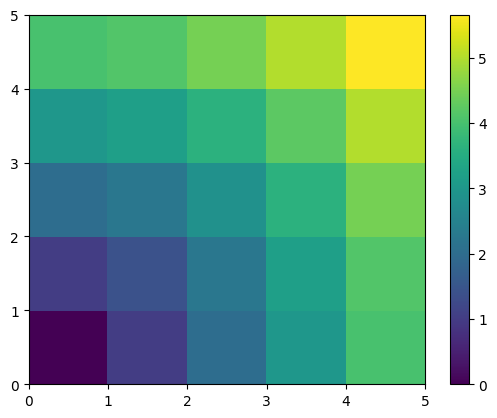

In [195]:
plt.pcolor(distance)
plt.colorbar()
plt.show()

**Remarque** : la fonction `np.ogrid` permet de créer directement les vecteurs x et y de l'exemple précédent, avec deux « dimensions significatives » :

In [196]:
x, y = np.ogrid[0:5, 0:5]
x, y

(array([[0],
        [1],
        [2],
        [3],
        [4]]),
 array([[0, 1, 2, 3, 4]]))

In [197]:
x.shape, y.shape
distance = np.sqrt(x ** 2 + y ** 2)

`np.ogrid` est donc très utile dès qu'on manipule des calculs sur une grille. De son côté, `np.mgrid` fournit directement des matrices pleines d'indices, pour les cas où l'on ne peut pas (ou ne veut pas) profiter du broadcasting :

In [198]:
x, y = np.mgrid[0:4, 0:4]
x

array([[0, 0, 0, 0],
       [1, 1, 1, 1],
       [2, 2, 2, 2],
       [3, 3, 3, 3]])

In [199]:
y

array([[0, 1, 2, 3],
       [0, 1, 2, 3],
       [0, 1, 2, 3],
       [0, 1, 2, 3]])

> **Exemple physique : le champ d'une charge ponctuelle sur une grille**
>
> Le potentiel électrostatique d'une charge $q$ placée à l'origine est $V = \dfrac{q}{4\pi\varepsilon_0 r}$. Grâce au broadcasting, on le calcule sur toute une grille en une seule expression :

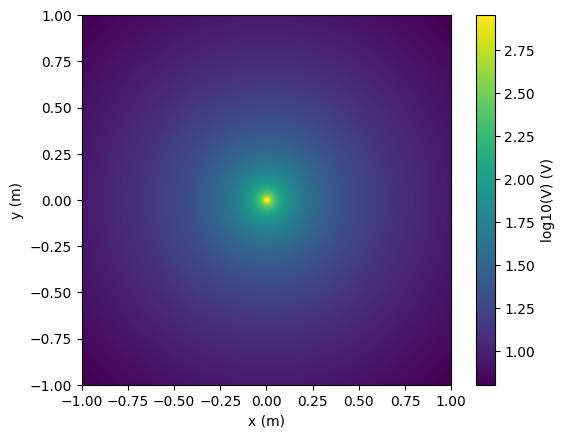

In [200]:
epsilon0 = 8.854e-12   # F/m
q = 1e-9               # 1 nC

x = np.linspace(-1, 1, 201)               # en mètres
y = np.linspace(-1, 1, 201)[:, np.newaxis]
r = np.sqrt(x**2 + y**2)
r[r < 0.01] = 0.01                        # évite la division par zéro à l'origine
V = q / (4 * np.pi * epsilon0 * r)

plt.imshow(np.log10(V), extent=[-1, 1, -1, 1], origin='lower')
plt.colorbar(label="log10(V) (V)")
plt.xlabel("x (m)"); plt.ylabel("y (m)")
plt.show()

## Manipulation de la forme des tableaux

### Aplatir

In [201]:
a = np.array([[1, 2, 3], [4, 5, 6]])
a.ravel()

array([1, 2, 3, 4, 5, 6])

In [202]:
a.T

array([[1, 4],
       [2, 5],
       [3, 6]])

In [203]:
a.T.ravel()

array([1, 4, 2, 5, 3, 6])

En dimensions supérieures, les dernières dimensions sont aplaties « en premier ».

### Changer la forme (*reshape*)

L'opération inverse de l'aplatissement :

In [204]:
a.shape

(2, 3)

In [205]:
b = a.ravel()
b = b.reshape((2, 3))
b

array([[1, 2, 3],
       [4, 5, 6]])

Ou bien :

In [206]:
a.reshape((2, -1))    # la valeur non précisée (-1) est déduite

array([[1, 2, 3],
       [4, 5, 6]])

> ⚠️ **Attention**
>
> `ndarray.reshape` **peut** renvoyer une vue (voir `help(np.reshape)`), ou une copie.


Par exemple :

In [207]:
b[0, 0] = 99
a

array([[99,  2,  3],
       [ 4,  5,  6]])

Attention, `reshape` peut aussi renvoyer une copie :

In [208]:
a = np.zeros((3, 2))
b = a.T.reshape(3*2)
b[0] = 9
a

array([[0., 0.],
       [0., 0.],
       [0., 0.]])

Pour comprendre cela, il faut en savoir plus sur l'organisation en mémoire d'un tableau NumPy.

### Ajouter une dimension

L'indexation avec l'objet `np.newaxis` permet d'ajouter un axe à un tableau (vous l'avez déjà vu plus haut, dans la section sur le broadcasting) :

In [209]:
z = np.array([1, 2, 3])
z

array([1, 2, 3])

In [210]:
z[:, np.newaxis]

array([[1],
       [2],
       [3]])

In [211]:
z[np.newaxis, :]

array([[1, 2, 3]])

### Permuter les dimensions

In [212]:
a = np.arange(4*3*2).reshape(4, 3, 2)
a.shape

(4, 3, 2)

In [213]:
a[0, 2, 1]

np.int64(5)

In [214]:
b = a.transpose(1, 2, 0)
b.shape

(3, 2, 4)

In [215]:
b[2, 1, 0]

np.int64(5)

Cela crée aussi une vue :

In [216]:
b[2, 1, 0] = -1
a[0, 2, 1]

np.int64(-1)

### Redimensionner

La taille d'un tableau peut être changée avec `ndarray.resize` :

In [217]:
a = np.arange(4)
a.resize((8,), refcheck=False)
a

array([0, 1, 2, 3, 0, 0, 0, 0])

Cependant, par défaut (`refcheck=True`), le tableau ne doit pas être référencé ailleurs :

In [218]:
# Erreur volontaire : un autre nom (b) désigne le même tableau
b = a
a.resize((4,))

ValueError: cannot resize an array that references or is referenced
by another object in this way.
Use the np.resize function to get a new resized copy or
 set refcheck=False to disable this check

> **Exercice**
>
> - Regardez la docstring de `reshape`, en particulier la section *Notes*, qui donne plus d'informations sur les copies et les vues.
> - Utilisez `flatten` comme alternative à `ravel`. Quelle est la différence ? (Indice : regardez lequel renvoie une vue et lequel une copie.)
> - Expérimentez avec `transpose` pour permuter les dimensions.

In [219]:
# Votre code ici

import numpy as np

# 1. Expérimenter avec reshape()
print("========== 1. RESHAPE ==========")

a = np.array([1, 2, 3, 4, 5, 6])
b = a.reshape(2, 3)

print("Tableau original :")
print(a)
print("Tableau après reshape(2, 3) :")
print(b)

# Vérifier si reshape renvoie une vue ou une copie
b[0, 0] = 100
print("Après modification de b :")
print("a =", a)
print("b =", b)
print("Remarque : reshape renvoie généralement une vue si possible, sinon une copie.\n")


# 2. Différence entre ravel() et flatten()
print("========== 2. RAVEL ET FLATTEN ==========")

# Avec ravel()
a = np.array([[1, 2, 3],
              [4, 5, 6]])

b = a.ravel()
b[0] = 100

print("Avec ravel() :")
print("Tableau original :")
print(a)
print("Tableau aplati :")
print(b)

# Avec flatten()
a = np.array([[1, 2, 3],
              [4, 5, 6]])

c = a.flatten()
c[0] = 100

print("\nAvec flatten() :")
print("Tableau original :")
print(a)
print("Tableau aplati :")
print(c)

print("\nDifférence :")
print("- ravel() renvoie une vue si possible, sinon une copie.")
print("- flatten() renvoie toujours une copie.")
print("- La modification de ravel() peut affecter le tableau original.")
print("- La modification de flatten() n'affecte pas le tableau original.\n")


# 3. Expérimenter avec transpose()
print("========== 3. TRANSPOSE ==========")

a = np.array([[1, 2, 3],
              [4, 5, 6]])

b = a.transpose()

print("Matrice originale :")
print(a)
print("Dimensions originales :", a.shape)

print("\nMatrice transposée :")
print(b)
print("Dimensions après transpose :", b.shape)

# Autre méthode : utiliser .T
print("\nTransposition avec .T :")
print(a.T)

# Transposition d'un tableau à trois dimensions
c = np.arange(24).reshape(2, 3, 4)

print("\nTableau à trois dimensions :")
print(c)
print("Dimensions originales :", c.shape)

d = c.transpose(1, 2, 0)

print("\nAprès transpose(1, 2, 0) :")
print(d)
print("Nouvelles dimensions :", d.shape)


# Conclusion générale
print("\n========== CONCLUSION ==========")
print("reshape() : modifie la forme du tableau.")
print("ravel() : transforme le tableau en 1D (vue si possible).")
print("flatten() : transforme le tableau en 1D (copie).")
print("transpose() : permute les dimensions du tableau.")


========== 1. RESHAPE ==========
Tableau original :
[1 2 3 4 5 6]
Tableau après reshape(2, 3) :
[[1 2 3]
 [4 5 6]]
Après modification de b :
a = [100   2   3   4   5   6]
b = [[100   2   3]
 [  4   5   6]]
Remarque : reshape renvoie généralement une vue si possible, sinon une copie.

========== 2. RAVEL ET FLATTEN ==========
Avec ravel() :
Tableau original :
[[100   2   3]
 [  4   5   6]]
Tableau aplati :
[100   2   3   4   5   6]

Avec flatten() :
Tableau original :
[[1 2 3]
 [4 5 6]]
Tableau aplati :
[100   2   3   4   5   6]

Différence :
- ravel() renvoie une vue si possible, sinon une copie.
- flatten() renvoie toujours une copie.
- La modification de ravel() peut affecter le tableau original.
- La modification de flatten() n'affecte pas le tableau original.

========== 3. TRANSPOSE ==========
Matrice originale :
[[1 2 3]
 [4 5 6]]
Dimensions originales : (2, 3)

Matrice transposée :
[[1 4]
 [2 5]
 [3 6]]
Dimensions après transpose : (3, 2)

Transposition avec .T :
[[1 4]
 [2 5]
 

## Trier des données

Tri le long d'un axe :

In [220]:
a = np.array([[4, 3, 5], [1, 2, 1]])
b = np.sort(a, axis=1)
b

array([[3, 4, 5],
       [1, 1, 2]])

Chaque ligne est triée séparément !

Tri sur place :

In [221]:
a.sort(axis=1)
a

array([[3, 4, 5],
       [1, 1, 2]])

Tri avec l'indexation avancée :

In [222]:
a = np.array([4, 3, 1, 2])
j = np.argsort(a)
j

array([2, 3, 1, 0])

In [223]:
a[j]

array([1, 2, 3, 4])

Trouver les minima et maxima :

In [224]:
a = np.array([4, 3, 1, 2])
j_max = np.argmax(a)
j_min = np.argmin(a)
j_max, j_min

(np.int64(0), np.int64(2))

**En résumé :**

- l'arithmétique, etc. se fait élément par élément ;
- algèbre linéaire de base : `@` ;
- réductions : `sum(axis=1)`, `std()`, `all()`, `any()` ;
- broadcasting : `a = np.arange(4); a[:,np.newaxis] + a[np.newaxis,:]` ;
- manipulation de forme : `a.ravel()`, `a.reshape(2, 2)` ;
- indexation avancée : `a[a > 3]`, `a[[2, 3]]` ;
- tri : `.sort()`, `np.sort`, `np.argsort`, `np.argmax`.


> **Exercice**
>
> - Essayez le tri sur place et le tri avec copie.
> - Créez des tableaux de différents types et triez-les.
> - Utilisez `all` ou `array_equal` pour vérifier les résultats.
> - Regardez `np.random.shuffle` pour créer plus vite des données à trier.
> - Combinez `ravel`, `sort` et `reshape`.
> - Regardez le mot-clé `axis` de `sort` et réécrivez l'exercice précédent avec.

In [225]:
# Votre code ici

import numpy as np

# 1. Tri sur place et tri avec copie
print("========== 1. TRI SUR PLACE ET TRI AVEC COPIE ==========")

a = np.array([5, 2, 8, 1, 9, 3])

# Tri sur place avec sort()
b = a.copy()
b.sort()

print("Tableau original :", a)
print("Tri sur place :", b)

# Tri avec copie avec np.sort()
c = np.sort(a)

print("\nTri avec copie :", c)
print("Tableau original après np.sort() :", a)


# 2. Créer et trier des tableaux de différents types
print("\n========== 2. TRI DE DIFFÉRENTS TYPES ==========")

# Tableau d'entiers
entiers = np.array([8, 3, 6, 1, 9, 2])
print("Entiers triés :", np.sort(entiers))

# Tableau de nombres décimaux
decimaux = np.array([3.5, 1.2, 8.7, 2.4, 5.1])
print("Décimaux triés :", np.sort(decimaux))

# Tableau de chaînes de caractères
chaines = np.array(["Python", "Java", "C++", "Angular"])
print("Chaînes triées :", np.sort(chaines))


# 3. Vérifier les résultats avec all() et array_equal()
print("\n========== 3. VÉRIFICATION DES RÉSULTATS ==========")

a = np.array([4, 1, 3, 2])
b = np.sort(a)

print("Tableau trié :", b)

# Vérifier si tous les éléments respectent l'ordre croissant
print("Vérification avec all() :", np.all(b[:-1] <= b[1:]))

# Comparer deux tableaux
attendu = np.array([1, 2, 3, 4])
print("Vérification avec array_equal() :",
      np.array_equal(b, attendu))


# 4. Utiliser np.random.shuffle() pour créer des données à trier
print("\n========== 4. RANDOM SHUFFLE ==========")

np.random.seed(42)

a = np.arange(1, 11)
np.random.shuffle(a)

print("Tableau mélangé :", a)

b = np.sort(a)
print("Tableau trié :", b)


# 5. Combiner ravel(), sort() et reshape()
print("\n========== 5. RAVEL, SORT ET RESHAPE ==========")

a = np.array([[9, 2, 7],
              [4, 1, 8]])

print("Tableau original :")
print(a)

# Transformer le tableau en une seule dimension
b = a.ravel()

# Trier le tableau aplati
b.sort()

print("\nTableau aplati et trié :")
print(b)

# Reformer le tableau en 2 lignes et 3 colonnes
c = b.reshape(2, 3)

print("\nTableau après reshape(2, 3) :")
print(c)


# 6. Utiliser axis avec sort()
print("\n========== 6. TRI AVEC AXIS ==========")

a = np.array([[9, 2, 7],
              [4, 1, 8]])

print("Tableau original :")
print(a)

# Tri par ligne (axis=1)
b = np.sort(a, axis=1)

print("\nTri par ligne (axis=1) :")
print(b)

# Tri par colonne (axis=0)
c = np.sort(a, axis=0)

print("\nTri par colonne (axis=0) :")
print(c)

# Tri de tous les éléments après aplatissement (axis=None)
d = np.sort(a, axis=None)

print("\nTri de tous les éléments (axis=None) :")
print(d)


# Vérification des résultats
print("\n========== VÉRIFICATION FINALE ==========")

print("Lignes triées :",
      np.all(b[:, :-1] <= b[:, 1:]))

print("Colonnes triées :",
      np.all(c[:-1, :] <= c[1:, :]))

print("Tous les éléments sont triés :",
      np.array_equal(d, np.array([1, 2, 4, 7, 8, 9])))


# Conclusion
print("\n========== CONCLUSION ==========")
print("sort() : trie le tableau sur place.")
print("np.sort() : retourne une copie triée.")
print("np.random.shuffle() : mélange les éléments du tableau.")
print("ravel() : transforme le tableau en une dimension.")
print("reshape() : modifie la forme du tableau.")
print("axis=0 : trie selon les colonnes.")
print("axis=1 : trie selon les lignes.")
print("axis=None : trie tous les éléments après aplatissement.")


========== 1. TRI SUR PLACE ET TRI AVEC COPIE ==========
Tableau original : [5 2 8 1 9 3]
Tri sur place : [1 2 3 5 8 9]

Tri avec copie : [1 2 3 5 8 9]
Tableau original après np.sort() : [5 2 8 1 9 3]

========== 2. TRI DE DIFFÉRENTS TYPES ==========
Entiers triés : [1 2 3 6 8 9]
Décimaux triés : [1.2 2.4 3.5 5.1 8.7]
Chaînes triées : ['Angular' 'C++' 'Java' 'Python']

========== 3. VÉRIFICATION DES RÉSULTATS ==========
Tableau trié : [1 2 3 4]
Vérification avec all() : True
Vérification avec array_equal() : True

========== 4. RANDOM SHUFFLE ==========
Tableau mélangé : [ 9  2  6  1  8  3 10  5  4  7]
Tableau trié : [ 1  2  3  4  5  6  7  8  9 10]

========== 5. RAVEL, SORT ET RESHAPE ==========
Tableau original :
[[9 2 7]
 [4 1 8]]

Tableau aplati et trié :
[1 2 4 7 8 9]

Tableau après reshape(2, 3) :
[[1 2 4]
 [7 8 9]]

========== 6. TRI AVEC AXIS ==========
Tableau original :
[[9 2 7]
 [4 1 8]]

Tri par ligne (axis=1) :
[[2 7 9]
 [1 4 8]]

Tri par colonne (axis=0) :
[[4 1 7]
 [9 2 

## Bilan : que faut-il savoir pour démarrer ?

- Savoir créer des tableaux : `array`, `arange`, `ones`, `zeros`.
- Connaître la forme d'un tableau avec `array.shape`, puis utiliser le découpage pour obtenir différentes vues : `array[::2]`, etc. Ajuster la forme avec `reshape` ou l'aplatir avec `ravel`.
- Obtenir un sous-ensemble d'éléments et/ou modifier leurs valeurs avec des masques, par exemple :

  ```python
  a[a < 0] = 0
  ```

- Connaître les opérations diverses sur les tableaux, comme la moyenne ou le maximum (`array.max()`, `array.mean()`). Inutile de tout retenir, mais ayez le réflexe de chercher dans la documentation (docs en ligne, `help()`) !
- Pour un usage avancé : maîtriser l'indexation avec des tableaux d'entiers, ainsi que le broadcasting. Connaître plus de fonctions NumPy pour gérer diverses opérations sur les tableaux.

# Exercices de synthèse


> **Exercice : trajectoire d'un projectile**
>
> Un projectile est lancé depuis le sol avec une vitesse $v_0 = 20\ \text{m/s}$ et un angle de $45^\circ$. Sans frottements :
>
> $$x(t) = v_0 \cos\theta\, t, \qquad y(t) = v_0 \sin\theta\, t - \tfrac12 g t^2$$
>
> 1. Créez un tableau `t` de 200 instants entre 0 et la durée totale du vol $T = 2 v_0 \sin\theta / g$.
> 2. Calculez `x` et `y` sans boucle.
> 3. Trouvez la hauteur maximale et la portée avec `max()` et `argmax()`.
> 4. Tracez la trajectoire `y(x)`.

========== RÉSULTATS ==========
Durée totale du vol : 2.88 s
Hauteur maximale : 10.19 m
Position horizontale au sommet : 20.49 m
Portée horizontale : 40.77 m


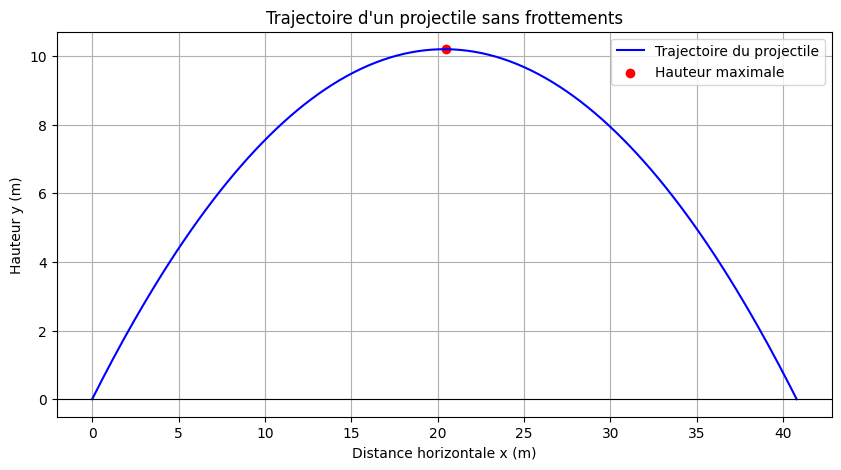

In [226]:
# Votre code ici

import numpy as np
import matplotlib.pyplot as plt

# 1. Définition des paramètres
v0 = 20          # Vitesse initiale en m/s
theta = np.radians(45)  # Angle converti en radians
g = 9.81         # Accélération de la pesanteur en m/s²

# 2. Calcul de la durée totale du vol
T = 2 * v0 * np.sin(theta) / g

# Création d'un tableau de 200 instants entre 0 et T
t = np.linspace(0, T, 200)

# 3. Calcul des positions x et y sans boucle
x = v0 * np.cos(theta) * t
y = v0 * np.sin(theta) * t - 0.5 * g * t**2

# 4. Calcul de la hauteur maximale et de la portée
hauteur_max = np.max(y)
indice_max = np.argmax(y)

# Position horizontale au sommet
x_sommet = x[indice_max]

# Portée horizontale
portee = np.max(x)

# 5. Affichage des résultats
print("========== RÉSULTATS ==========")
print(f"Durée totale du vol : {T:.2f} s")
print(f"Hauteur maximale : {hauteur_max:.2f} m")
print(f"Position horizontale au sommet : {x_sommet:.2f} m")
print(f"Portée horizontale : {portee:.2f} m")

# 6. Tracé de la trajectoire
plt.figure(figsize=(10, 5))

plt.plot(x, y, label="Trajectoire du projectile", color="blue")

# Marquer le point le plus haut
plt.scatter(x_sommet, hauteur_max, color="red",
            label="Hauteur maximale")

plt.xlabel("Distance horizontale x (m)")
plt.ylabel("Hauteur y (m)")
plt.title("Trajectoire d'un projectile sans frottements")

plt.grid(True)
plt.legend()
plt.axhline(0, color="black", linewidth=0.8)

plt.show()


Hauteur max : 10.19 m (à t = 1.45 s)
Portée      : 40.77 m


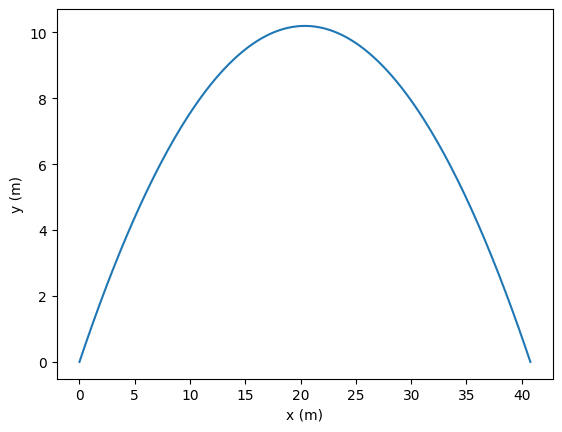

In [227]:
#@title Solution { display-mode: "form" }
g, v0, theta = 9.81, 20.0, np.radians(45)
T = 2 * v0 * np.sin(theta) / g
t = np.linspace(0, T, 200)
x = v0 * np.cos(theta) * t
y = v0 * np.sin(theta) * t - 0.5 * g * t**2

print(f"Hauteur max : {y.max():.2f} m (à t = {t[y.argmax()]:.2f} s)")
print(f"Portée      : {x[-1]:.2f} m")

plt.plot(x, y)
plt.xlabel("x (m)"); plt.ylabel("y (m)")
plt.show()

> **Exercice : Mesures et statistiques**
>
> On mesure 10 fois la période d'un pendule : `T = [2.01, 1.98, 2.03, 2.00, 1.99, 2.02, 2.05, 1.97, 2.00, 2.01]` (en s).
>
> 1. Calculez la moyenne et l'écart-type (avec `ddof=1` pour l'écart-type expérimental).
> 2. Calculez l'incertitude-type sur la moyenne, $u = s/\sqrt{N}$.
> 3. Déduisez la valeur de $g = 4\pi^2 L / T^2$ pour $L = 1{,}00\ \text{m}$.

In [228]:
# Votre code ici

import numpy as np

# 1. Données expérimentales : période du pendule (en secondes)
T = np.array([2.01, 1.98, 2.03, 2.00, 1.99,
              2.02, 2.05, 1.97, 2.00, 2.01])

# Longueur du pendule (en mètres)
L = 1.00

# Nombre de mesures
N = len(T)

# 2. Calcul de la moyenne
T_moy = np.mean(T)

# 3. Calcul de l'écart-type expérimental (ddof=1)
s = np.std(T, ddof=1)

# 4. Calcul de l'incertitude-type sur la moyenne
u = s / np.sqrt(N)

# 5. Calcul de l'accélération de la pesanteur g
g = (4 * np.pi**2 * L) / T_moy**2

# 6. Affichage des résultats
print("========== RÉSULTATS EXPÉRIMENTAUX ==========")

print(f"Nombre de mesures : N = {N}")
print(f"Période moyenne : T_moy = {T_moy:.4f} s")
print(f"Écart-type expérimental : s = {s:.5f} s")
print(f"Incertitude-type sur la moyenne : u = {u:.5f} s")

print("\n========== ACCÉLÉRATION DE LA PESANTEUR ==========")

print(f"Longueur du pendule : L = {L:.2f} m")
print(f"Valeur de g : g = {g:.4f} m/s²")

# 7. Résultat avec l'incertitude sur g (propagation au premier ordre)
u_g = 2 * g * u / T_moy

print(f"Incertitude sur g : u(g) = {u_g:.4f} m/s²")
print(f"Résultat final : g = ({g:.2f} ± {u_g:.2f}) m/s²")


========== RÉSULTATS EXPÉRIMENTAUX ==========
Nombre de mesures : N = 10
Période moyenne : T_moy = 2.0060 s
Écart-type expérimental : s = 0.02366 s
Incertitude-type sur la moyenne : u = 0.00748 s

========== ACCÉLÉRATION DE LA PESANTEUR ==========
Longueur du pendule : L = 1.00 m
Valeur de g : g = 9.8107 m/s²
Incertitude sur g : u(g) = 0.0732 m/s²
Résultat final : g = (9.81 ± 0.07) m/s²


In [229]:
#@title Solution { display-mode: "form" }
T = np.array([2.01, 1.98, 2.03, 2.00, 1.99, 2.02, 2.05, 1.97, 2.00, 2.01])
moy = T.mean()
s = T.std(ddof=1)
u = s / np.sqrt(T.size)
print(f"T = {moy:.3f} ± {u:.3f} s  (s = {s:.3f} s)")

L = 1.00
g = 4 * np.pi**2 * L / moy**2
print(f"g = {g:.2f} m/s²")

T = 2.006 ± 0.007 s  (s = 0.024 s)
g = 9.81 m/s²


---

*Fin du carnet 3. Suite : carnet 4 — Matplotlib.*